         year    eps  delta                  method  hospitals  loss_harm  cal_harm  either  point_above  nonlocal_  mean_loss_diff  auroc_gain
0   2022 test  0.005  0.010                  Pooled        126        0.6       4.8     5.2         68.8        NaN          0.0029      0.0005
1   2022 test  0.005  0.010             Fine-tuning        126        0.0       0.0     0.0          6.8        NaN         -0.0004      0.0035
2   2022 test  0.005  0.010       Pooled, certified        126        0.0       0.0     0.0          0.0       17.0          0.0000      0.0002
3   2022 test  0.005  0.010  Fine-tuning, certified        126        0.0       0.0     0.0          0.0       17.4          0.0000     -0.0000
4   2022 test  0.010  0.015                  Pooled        126        0.4       2.0     2.4         48.8        NaN          0.0029      0.0005
5   2022 test  0.010  0.015             Fine-tuning        126        0.0       0.0     0.0          1.8        NaN         -0.0004     

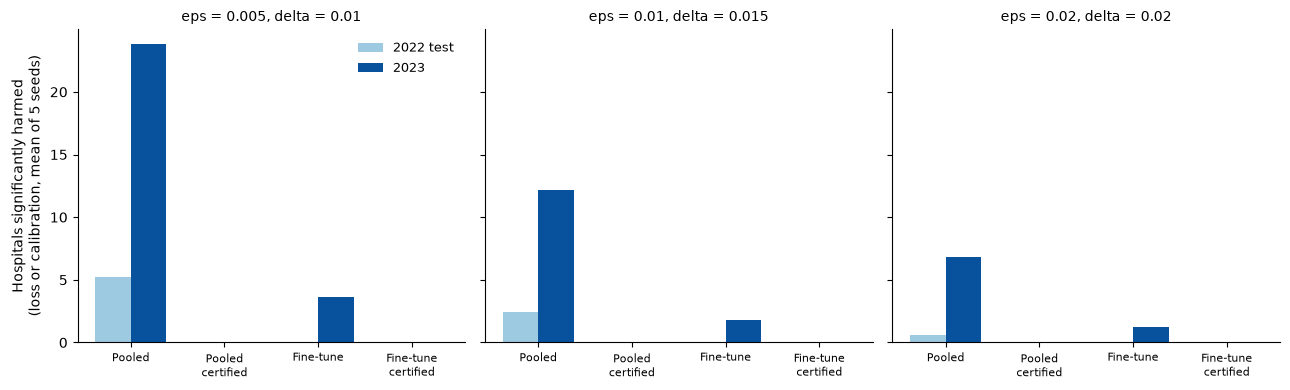

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
from scipy import stats
from statsmodels.stats.multitest import multipletests
os.makedirs("../outputs/figures", exist_ok=True)
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
seeds = [110, 111, 112, 113, 114]
A = {s: pd.read_csv(f"../outputs/tables/cert_full_seed{s}.csv").copy() for s in seeds}
Tm = {s: pd.read_csv(f"../outputs/tables/temporal_2023_seed{s}.csv").copy() for s in seeds}
HEAD = [(0.005, 0.01), (0.01, 0.015), (0.02, 0.02)]

def loss_mask(r, pre, eps):
    d, se = r[f"{pre}__diff"].values, r[f"{pre}__se"].values
    z = np.where(se > 0, (d - eps) / np.where(se > 0, se, 1), -np.inf)
    return multipletests(1 - stats.norm.cdf(z), alpha=0.05, method="holm")[0]

def row(r, pre, eps, delta):
    lm = loss_mask(r, pre, eps); cm = r[f"{pre}__gaplb"].values > delta
    return dict(loss_harm=lm.sum(), cal_harm=cm.sum(), either=(lm | cm).sum(), point_above=(r[f"{pre}__gapmax"] > delta).sum(),
                nonlocal_=(r[f"{pre}__blend"] > 0).sum() if "cert" in pre else np.nan,
                mean_loss_diff=r[f"{pre}__diff"].mean(), auroc_gain=(r[f"{pre}__auroc"] - r["local__auroc"]).mean())

rows = []
for year, D in (("2022 test", A), ("2023", Tm)):
    for eps, delta in HEAD:
        for label, pre in [("Pooled", "pool_full"), ("Fine-tuning", "ft_full"),
                           ("Pooled, certified", f"cert_pool_e{eps}_d{delta}"), ("Fine-tuning, certified", f"cert_ft_e{eps}_d{delta}")]:
            res = pd.DataFrame([row(D[s], pre, eps, delta) for s in seeds]).mean()
            rows.append({"year": year, "eps": eps, "delta": delta, "method": label, "hospitals": len(D[seeds[0]]), **res.to_dict()})
T17 = pd.DataFrame(rows)
T17.to_csv("../outputs/tables/T17_temporal.csv", index=False)
print(T17.round(4).to_string())

fig, ax = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
meths = ["Pooled", "Pooled, certified", "Fine-tuning", "Fine-tuning, certified"]
for a, (eps, delta) in zip(ax, HEAD):
    for i, (yr, c) in enumerate([("2022 test", "#9ecae1"), ("2023", "#08519c")]):
        v = [T17[(T17.year == yr) & (T17.eps == eps) & (T17.method == m)].either.values[0] for m in meths]
        a.bar(np.arange(4) + (i - 0.5) * 0.38, v, 0.38, color=c, label=yr)
    a.set_xticks(range(4)); a.set_xticklabels(["Pooled", "Pooled\ncertified", "Fine-tune", "Fine-tune\ncertified"], fontsize=8)
    a.set_title(f"eps = {eps}, delta = {delta}", fontsize=10)
ax[0].set_ylabel("Hospitals significantly harmed\n(loss or calibration, mean of 5 seeds)"); ax[0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig("../outputs/figures/fig16_temporal.png", dpi=300); plt.savefig("../outputs/figures/fig16_temporal.pdf"); plt.show()

        version    eps  delta                  method  either  point_above  nonlocal_  mean_loss_diff  auroc_gain  local_auroc
0   without APR  0.005  0.010                  Pooled     5.2         68.8        NaN          0.0029      0.0005       0.8145
1   without APR  0.005  0.010             Fine-tuning     0.0          6.8        NaN         -0.0004      0.0035       0.8145
2   without APR  0.005  0.010       Pooled, certified     0.0          0.0       17.0          0.0000      0.0002       0.8145
3   without APR  0.005  0.010  Fine-tuning, certified     0.0          0.0       17.4          0.0000     -0.0000       0.8145
4   without APR  0.010  0.015                  Pooled     2.4         48.8        NaN          0.0029      0.0005       0.8145
5   without APR  0.010  0.015             Fine-tuning     0.0          1.8        NaN         -0.0004      0.0035       0.8145
6   without APR  0.010  0.015       Pooled, certified     0.0          0.0       55.8          0.0001      0.00

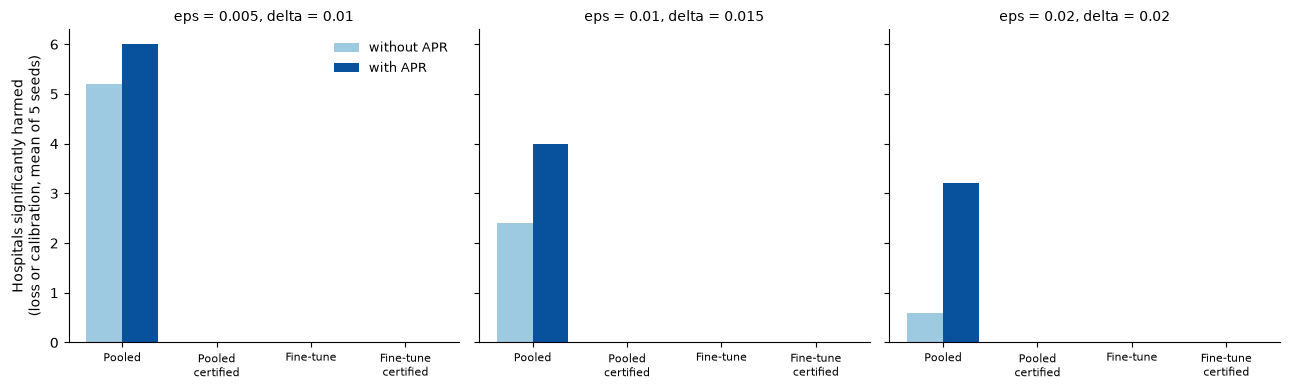

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
from scipy import stats
from statsmodels.stats.multitest import multipletests
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
seeds = [110, 111, 112, 113, 114]; HEAD = [(0.005, 0.01), (0.01, 0.015), (0.02, 0.02)]
V = {"without APR": {s: pd.read_csv(f"../outputs/tables/cert_full_seed{s}.csv").copy() for s in seeds},
     "with APR": {s: pd.read_csv(f"../outputs/tables/cert_full_seed{s}_apr.csv").copy() for s in seeds}}

def lm(r, pre, eps):
    d, se = r[f"{pre}__diff"].values, r[f"{pre}__se"].values
    z = np.where(se > 0, (d - eps) / np.where(se > 0, se, 1), -np.inf)
    return multipletests(1 - stats.norm.cdf(z), alpha=0.05, method="holm")[0]

rows = []
for ver, D in V.items():
    for eps, delta in HEAD:
        for label, pre in [("Pooled", "pool_full"), ("Fine-tuning", "ft_full"),
                           ("Pooled, certified", f"cert_pool_e{eps}_d{delta}"), ("Fine-tuning, certified", f"cert_ft_e{eps}_d{delta}")]:
            out = []
            for s in seeds:
                r = D[s]; l = lm(r, pre, eps); c = r[f"{pre}__gaplb"].values > delta
                out.append(dict(either=(l | c).sum(), point_above=(r[f"{pre}__gapmax"] > delta).sum(),
                                nonlocal_=(r[f"{pre}__blend"] > 0).sum() if "cert" in pre else np.nan,
                                mean_loss_diff=r[f"{pre}__diff"].mean(), auroc_gain=(r[f"{pre}__auroc"] - r["local__auroc"]).mean(),
                                local_auroc=r["local__auroc"].mean()))
            rows.append({"version": ver, "eps": eps, "delta": delta, "method": label, **pd.DataFrame(out).mean().to_dict()})
T19 = pd.DataFrame(rows); T19.to_csv("../outputs/tables/T19_apr_sensitivity.csv", index=False)
print(T19.round(4).to_string())

fig, ax = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
meths = ["Pooled", "Pooled, certified", "Fine-tuning", "Fine-tuning, certified"]
for a, (eps, delta) in zip(ax, HEAD):
    for i, (ver, c) in enumerate([("without APR", "#9ecae1"), ("with APR", "#08519c")]):
        v = [T19[(T19.version == ver) & (T19.eps == eps) & (T19.method == m)].either.values[0] for m in meths]
        a.bar(np.arange(4) + (i - 0.5) * 0.38, v, 0.38, color=c, label=ver)
    a.set_xticks(range(4)); a.set_xticklabels(["Pooled", "Pooled\ncertified", "Fine-tune", "Fine-tune\ncertified"], fontsize=8)
    a.set_title(f"eps = {eps}, delta = {delta}", fontsize=10)
ax[0].set_ylabel("Hospitals significantly harmed\n(loss or calibration, mean of 5 seeds)"); ax[0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig("../outputs/figures/fig20_apr_sensitivity.png", dpi=300); plt.savefig("../outputs/figures/fig20_apr_sensitivity.pdf"); plt.show()

Logistic regression seeds used: [110, 111, 112, 113, 114]
Gradient boosting seeds used: [110, 111, 112, 113, 114]
MLP seeds used: [111, 112, 113, 114]
                  class    eps  delta             method  seeds  loss_harm  cal_harm  either  point_above  nonlocal_  mean_loss_diff  auroc_gain  local_auroc  lr_local_auroc
0   Logistic regression  0.005  0.010             Pooled      5       0.60      4.80    5.20        68.80        NaN          0.0029      0.0005       0.8145          0.8145
1   Logistic regression  0.005  0.010  Pooled, certified      5       0.00      0.00    0.00         0.00      17.00          0.0000      0.0002       0.8145          0.8145
2   Logistic regression  0.010  0.015             Pooled      5       0.40      2.00    2.40        48.80        NaN          0.0029      0.0005       0.8145          0.8145
3   Logistic regression  0.010  0.015  Pooled, certified      5       0.00      0.00    0.00         0.00      55.80          0.0001      0.0010       0.

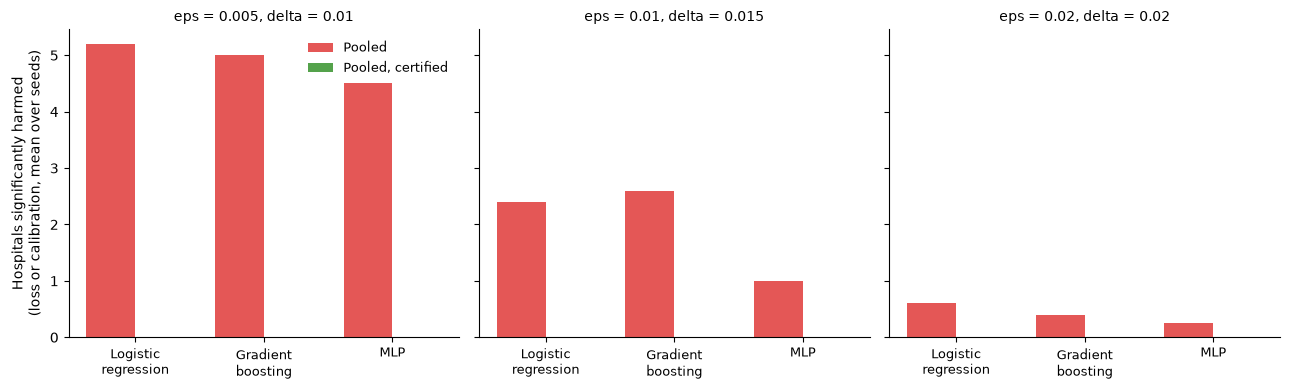

In [2]:
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
HEAD = [(0.005, 0.01), (0.01, 0.015), (0.02, 0.02)]
CLASSES = {"Logistic regression": ("lr", range(110, 115)), "Gradient boosting": ("gbm", range(110, 115)), "MLP": ("mlp", range(111, 115))}

def path(kind, s):
    return f"../outputs/tables/cert_full_seed{s}.csv" if kind == "lr" else f"../outputs/tables/model_{kind}_seed{s}.csv"
def cert_prefix(kind, eps, delta):
    return f"cert_pool_e{eps}_d{delta}" if kind == "lr" else f"cert_e{eps}_d{delta}"
def loss_mask(r, pre, eps):
    d, se = r[f"{pre}__diff"].values, r[f"{pre}__se"].values
    z = np.where(se > 0, (d - eps) / np.where(se > 0, se, 1), -np.inf)
    return multipletests(1 - stats.norm.cdf(z), alpha=0.05, method="holm")[0]

rows = []
for cname, (kind, seeds) in CLASSES.items():
    D = {s: pd.read_csv(path(kind, s)).copy() for s in seeds if os.path.exists(path(kind, s))}
    print(cname, "seeds used:", sorted(D))
    for eps, delta in HEAD:
        for label, pre in [("Pooled", "pool_full"), ("Pooled, certified", cert_prefix(kind, eps, delta))]:
            out = []
            for r in D.values():
                lm = loss_mask(r, pre, eps); cm = r[f"{pre}__gaplb"].values > delta
                out.append(dict(loss_harm=lm.sum(), cal_harm=cm.sum(), either=(lm | cm).sum(), point_above=(r[f"{pre}__gapmax"] > delta).sum(),
                                nonlocal_=(r[f"{pre}__blend"] > 0).sum() if "cert" in pre else np.nan,
                                mean_loss_diff=r[f"{pre}__diff"].mean(), auroc_gain=(r[f"{pre}__auroc"] - r["local__auroc"]).mean(),
                                local_auroc=r["local__auroc"].mean(),
                                lr_local_auroc=r["local__auroc"].mean() if kind == "lr" else r["lr_local_auroc"].mean()))
            rows.append({"class": cname, "eps": eps, "delta": delta, "method": label, "seeds": len(D), **pd.DataFrame(out).mean().to_dict()})
T14 = pd.DataFrame(rows); T14.to_csv("../outputs/tables/T14_model_class.csv", index=False)
print(T14.round(4).to_string())

fig, ax = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
names = list(CLASSES)
for a, (eps, delta) in zip(ax, HEAD):
    for i, (m, c) in enumerate([("Pooled", "#E45756"), ("Pooled, certified", "#54A24B")]):
        v = [T14[(T14["class"] == n) & (T14.eps == eps) & (T14.method == m)].either.values[0] for n in names]
        a.bar(np.arange(3) + (i - 0.5) * 0.38, v, 0.38, color=c, label=m)
    a.set_xticks(range(3)); a.set_xticklabels(["Logistic\nregression", "Gradient\nboosting", "MLP"], fontsize=9)
    a.set_title(f"eps = {eps}, delta = {delta}", fontsize=10)
ax[0].set_ylabel("Hospitals significantly harmed\n(loss or calibration, mean over seeds)"); ax[0].legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.savefig("../outputs/figures/fig15_model_class.png", dpi=300); plt.savefig("../outputs/figures/fig15_model_class.pdf"); plt.show()

     eps  delta                  method  client_seeds  loss_harm  cal_harm_sig  cal_point_above  nonlocal  mean_loss_diff  mean_auroc_gain
0  0.005  0.010                  Pooled            20          0             0               14       NaN         -0.0244           0.0251
1  0.005  0.010       Pooled, certified            20          0             0                0       0.0          0.0000           0.0000
2  0.005  0.010  Fine-tuning, certified            20          0             0                0       0.0          0.0000           0.0000
3  0.010  0.015                  Pooled            20          0             0                7       NaN         -0.0244           0.0251
4  0.010  0.015       Pooled, certified            20          0             0                0       0.0          0.0000           0.0000
5  0.010  0.015  Fine-tuning, certified            20          0             0                0       0.0          0.0000           0.0000
6  0.020  0.020            

C:\Users\HP\AppData\Local\Temp\ipykernel_21904\1848600409.py:29: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  R["nl_pool"] = sum((R[f"cert_pool_e{e}_d{d}__blend"] > 0).astype(int) for e, d in HEAD)
C:\Users\HP\AppData\Local\Temp\ipykernel_21904\1848600409.py:30: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  R["nl_ft"] = sum((R[f"cert_ft_e{e}_d{d}__blend"] > 0).astype(int) for e, d in HEAD)


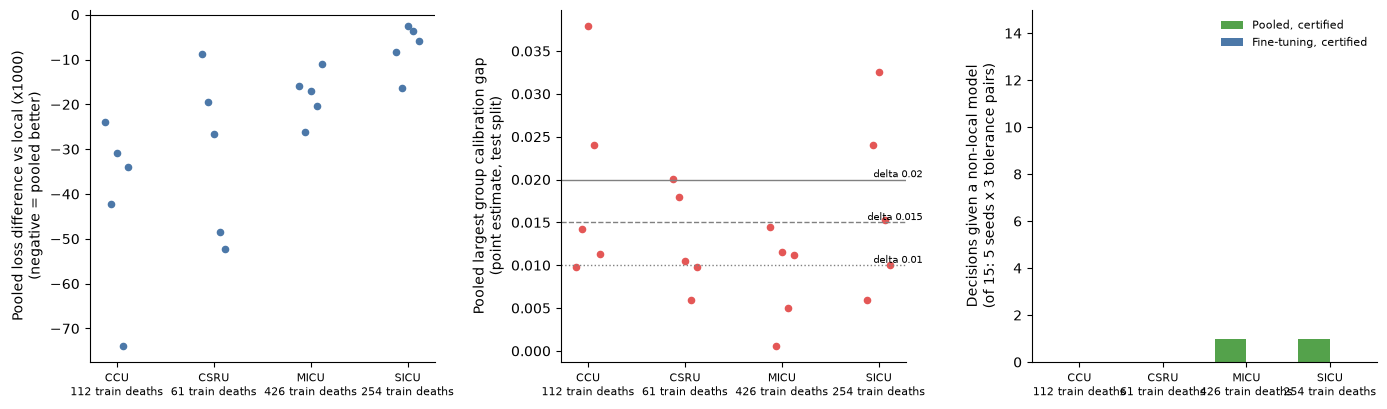

In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
R = pd.concat([pd.read_csv(f"../outputs/tables/icu2012_seed{s}.csv") for s in range(200, 205)], ignore_index=True)
HEAD = [(0.005, 0.01), (0.01, 0.015), (0.02, 0.02)]
UNIT = {1: "CCU", 2: "CSRU", 3: "MICU", 4: "SICU"}

def loss_harm(r, pre, eps):
    se, d = r[f"{pre}__se"], r[f"{pre}__diff"]
    return bool(se > 0 and (1 - stats.norm.cdf((d - eps) / se)) * 4 < 0.05)      # one-sided, Bonferroni over 4 units

rows = []
for eps, delta in HEAD:
    for label, pre in [("Pooled", "pool_full"), ("Pooled, certified", f"cert_pool_e{eps}_d{delta}"),
                       ("Fine-tuning, certified", f"cert_ft_e{eps}_d{delta}")]:
        lh = R.apply(lambda r: loss_harm(r, pre, eps), axis=1)
        rows.append({"eps": eps, "delta": delta, "method": label, "client_seeds": len(R), "loss_harm": int(lh.sum()),
                     "cal_harm_sig": int((R[f"{pre}__gaplb"] > delta).sum()), "cal_point_above": int((R[f"{pre}__gapmax"] > delta).sum()),
                     "nonlocal": int((R[f"{pre}__blend"] > 0).sum()) if "cert" in pre else np.nan,
                     "mean_loss_diff": R[f"{pre}__diff"].mean(), "mean_auroc_gain": (R[f"{pre}__auroc"] - R["local__auroc"]).mean()})
T18 = pd.DataFrame(rows); T18.to_csv("../outputs/tables/T18_icu2012.csv", index=False)
print(T18.round(4).to_string())
cert = T18[T18.method.str.contains("certified")]
print("\ncriterion: certified harmed on loss or calibration (significant):", int(cert.loss_harm.sum() + cert.cal_harm_sig.sum()),
      "| above tolerance by point estimate:", int(cert.cal_point_above.sum()))

R["pool_auroc_gain"] = R["pool_full__auroc"] - R["local__auroc"]
R["gap_above_001"] = (R["pool_full__gapmax"] > 0.01).astype(int)
R["nl_pool"] = sum((R[f"cert_pool_e{e}_d{d}__blend"] > 0).astype(int) for e, d in HEAD)
R["nl_ft"] = sum((R[f"cert_ft_e{e}_d{d}__blend"] > 0).astype(int) for e, d in HEAD)
U = R.groupby("icu_type").agg(train_stays=("n_train", "first"), train_deaths=("deaths_train", "first"), test_deaths=("deaths_test", "first"),
        local_auroc=("local__auroc", "mean"), pooled_loss_diff=("pool_full__diff", "mean"), pooled_auroc_gain=("pool_auroc_gain", "mean"),
        seeds_gap_above_delta001=("gap_above_001", "sum"), certified_pooled_nonlocal_of15=("nl_pool", "sum"),
        certified_ft_nonlocal_of15=("nl_ft", "sum"))
U.index = [UNIT[i] for i in U.index]; U.round(4).to_csv("../outputs/tables/T18b_icu2012_by_unit.csv"); print("\n", U.round(4).to_string())

fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
xl = [f"{UNIT[u]}\n{int(U.train_deaths.iloc[i])} train deaths" for i, u in enumerate([1, 2, 3, 4])]
for i, u in enumerate([1, 2, 3, 4]):
    t = R[R.icu_type == u]; xs = np.full(len(t), i) + np.linspace(-0.12, 0.12, len(t))
    ax[0].scatter(xs, 1000 * t["pool_full__diff"], c="#4C78A8", s=20)
    ax[1].scatter(xs, t["pool_full__gapmax"], c="#E45756", s=20)
ax[0].axhline(0, c="k", lw=0.8); ax[0].set_ylabel("Pooled loss difference vs local (x1000)\n(negative = pooled better)")
for dl, ls in zip([0.01, 0.015, 0.02], [":", "--", "-"]):
    ax[1].axhline(dl, c="grey", ls=ls, lw=1); ax[1].text(3.45, dl, f"delta {dl}", fontsize=7, va="bottom", ha="right")
ax[1].set_ylabel("Pooled largest group calibration gap\n(point estimate, test split)")
for a in ax[:2]:
    a.set_xticks(range(4)); a.set_xticklabels(xl, fontsize=8)
ax[2].bar(np.arange(4) - 0.19, U.certified_pooled_nonlocal_of15, 0.38, color="#54A24B", label="Pooled, certified")
ax[2].bar(np.arange(4) + 0.19, U.certified_ft_nonlocal_of15, 0.38, color="#4C78A8", label="Fine-tuning, certified")
ax[2].set_xticks(range(4)); ax[2].set_xticklabels(xl, fontsize=8); ax[2].set_ylim(0, 15)
ax[2].set_ylabel("Decisions given a non-local model\n(of 15: 5 seeds x 3 tolerance pairs)"); ax[2].legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.savefig("../outputs/figures/fig17_icu2012.png", dpi=300); plt.savefig("../outputs/figures/fig17_icu2012.pdf"); plt.show()

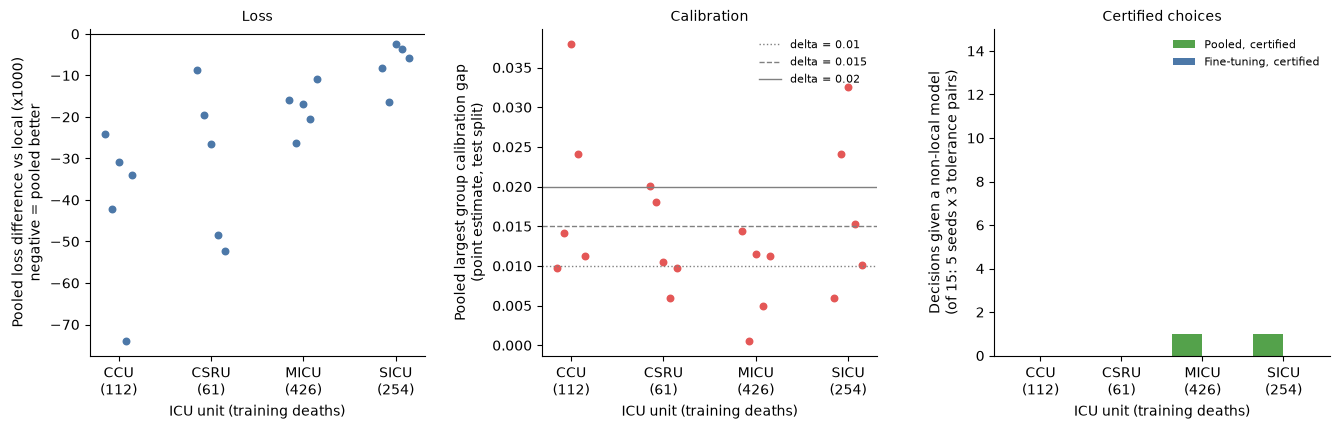

In [4]:
R = R.copy()
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
units = [1, 2, 3, 4]
xl = [f"{UNIT[u]}\n({int(U.train_deaths.iloc[i])})" for i, u in enumerate(units)]

for i, u in enumerate(units):
    t = R[R.icu_type == u]; xs = np.full(len(t), i) + np.linspace(-0.15, 0.15, len(t))
    ax[0].scatter(xs, 1000 * t["pool_full__diff"], c="#4C78A8", s=22)
    ax[1].scatter(xs, t["pool_full__gapmax"], c="#E45756", s=22)
ax[0].axhline(0, c="k", lw=0.8)
ax[0].set_ylabel("Pooled loss difference vs local (x1000)\nnegative = pooled better")
ax[0].set_title("Loss", fontsize=10)
for dl, ls in zip([0.01, 0.015, 0.02], [":", "--", "-"]):
    ax[1].axhline(dl, c="grey", ls=ls, lw=1, label=f"delta = {dl}")
ax[1].set_ylabel("Pooled largest group calibration gap\n(point estimate, test split)")
ax[1].set_title("Calibration", fontsize=10); ax[1].legend(frameon=False, fontsize=8, loc="upper right")
ax[2].bar(np.arange(4) - 0.19, U.certified_pooled_nonlocal_of15, 0.38, color="#54A24B", label="Pooled, certified")
ax[2].bar(np.arange(4) + 0.19, U.certified_ft_nonlocal_of15, 0.38, color="#4C78A8", label="Fine-tuning, certified")
ax[2].set_ylim(0, 15); ax[2].set_title("Certified choices", fontsize=10)
ax[2].set_ylabel("Decisions given a non-local model\n(of 15: 5 seeds x 3 tolerance pairs)")
ax[2].legend(frameon=False, fontsize=8, loc="upper right")
for a in ax:
    a.set_xticks(range(4)); a.set_xticklabels(xl, fontsize=10)
    a.set_xlabel("ICU unit (training deaths)")
plt.subplots_adjust(wspace=0.35, bottom=0.2)
plt.savefig("../outputs/figures/fig17_icu2012.png", dpi=300); plt.savefig("../outputs/figures/fig17_icu2012.pdf"); plt.show()